# MODUL PRAKTIKUM DATA MINING
## Association Rule Mining (Market Basket Analysis)

Notebook ini merupakan file terpisah untuk mengerjakan **Tugas 1 (Bagian 5.1)** pada Modul Praktikum Data Mining – Association Rule Mining (Market Basket Analysis), 2026.

### Dataset yang digunakan
Dataset transaksi yang digunakan tetap sama dengan notebook praktikum utama, yaitu `transactions_arm_praktikum.csv`, berisi 60 transaksi dan 12 jenis item. File CSV tersebut perlu diletakkan dalam folder yang sama dengan notebook ini.

### Alur pengerjaan
1. Menjalankan Apriori dengan `min_support = 0.10` dan membandingkannya dengan hasil `min_support = 0.15`.
2. Menaikkan `min_confidence` menjadi 0.7 dan mengidentifikasi aturan yang masih lolos maupun gugur.
3. Membuat grafik pengaruh `min_confidence` terhadap jumlah aturan asosiasi.
4. Membahas trade-off penggunaan ambang batas `min_confidence` rendah dan tinggi.

Penulisan, struktur kode, nama variabel, dan tampilan visualisasi mengikuti notebook praktikum utama. Perubahan hanya dilakukan pada bagian yang diperlukan untuk menjawab instruksi Tugas 1.

## Persiapan Data dan Pustaka

Tahap persiapan berikut digunakan agar notebook tugas dapat dijalankan secara terpisah. Data transaksi dibaca dari file CSV yang sama dengan praktikum utama, kemudian diubah menjadi matriks one-hot menggunakan `TransactionEncoder`.

In [1]:
%pip install -q mlxtend

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

# Membaca dataset transaksi mentah
data = pd.read_csv('transactions_arm_praktikum.csv')

# transactions: list berisi transaksi (daftar item per transaksi)
transactions = [items.split(', ') for items in data['Items']]

print('Jumlah transaksi:', len(transactions))
for i, t in enumerate(transactions[:5], 1):
    print(f'T{i}: {t}')

Jumlah transaksi: 60
T1: ['Gula', 'Kopi', 'Susu']
T2: ['Gula', 'Kopi', 'Susu']
T3: ['Mentega', 'Roti', 'Susu', 'Telur']
T4: ['Mie Instan']
T5: ['Keju', 'Roti', 'Susu', 'Telur']


In [3]:
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df = pd.DataFrame(te_ary, columns=te.columns_)

print('Ukuran matriks one-hot:', df.shape)
print(df.iloc[:5, :6])

Ukuran matriks one-hot: (60, 12)
    Gula  Kecap   Keju   Kopi  Mentega  Mie Instan
0   True  False  False   True    False       False
1   True  False  False   True    False       False
2  False  False  False  False     True       False
3  False  False  False  False    False        True
4  False  False   True  False    False       False


### 1. Jalankan Apriori dengan `min_support = 0.10` dan `min_confidence = 0.5`, lalu bandingkan dengan hasil Bagian 4.3–4.4.

Nilai `min_support` diturunkan dari 0.15 menjadi 0.10, sedangkan `min_confidence` tetap 0.5. Hasilnya kemudian dibandingkan dengan hasil praktikum utama pada `min_support = 0.15`.

In [4]:
freq_apriori_010 = apriori(df, min_support=0.10, use_colnames=True)
rules_010 = association_rules(
    freq_apriori_010,
    metric='confidence',
    min_threshold=0.5
)

print('min_support = 0.10')
print('Jumlah frequent itemset:', len(freq_apriori_010))
print('Jumlah aturan asosiasi:', len(rules_010))

print('\nPembanding min_support = 0.15')

freq_apriori_015 = apriori(df, min_support=0.15, use_colnames=True)
rules_015 = association_rules(
    freq_apriori_015,
    metric='confidence',
    min_threshold=0.5
)

print('Jumlah frequent itemset:', len(freq_apriori_015))
print('Jumlah aturan asosiasi:', len(rules_015))

min_support = 0.10
Jumlah frequent itemset: 19
Jumlah aturan asosiasi: 20

Pembanding min_support = 0.15
Jumlah frequent itemset: 17
Jumlah aturan asosiasi: 18


**Analisis hasil:**

Pada `min_support = 0.10`, diperoleh **19 frequent itemset dan 20 aturan asosiasi**. Sementara itu, pada `min_support = 0.15`, diperoleh **17 frequent itemset dan 18 aturan asosiasi**. Dengan demikian, penurunan ambang batas minimum support menghasilkan dua frequent itemset dan dua aturan asosiasi tambahan.

Hal ini terjadi karena ambang batas yang lebih rendah memungkinkan itemset dengan frekuensi kemunculan yang lebih sedikit tetap memenuhi syarat untuk diproses. Akibatnya, lebih banyak kombinasi item dapat ditemukan dan dibentuk menjadi aturan asosiasi.

### 2. Naikkan `min_confidence` menjadi 0.7. Catat aturan yang masih lolos dan aturan yang gugur.

Pengujian menggunakan frequent itemset dari Bagian 4.3, yaitu hasil Apriori dengan `min_support = 0.15`. Aturan awal dibentuk dengan `min_confidence = 0.5`, kemudian dibandingkan dengan aturan yang memenuhi `min_confidence = 0.7`.

In [5]:
rules_conf_070 = association_rules(
    freq_apriori_015,
    metric='confidence',
    min_threshold=0.7
)

print('Jumlah aturan pada min_confidence = 0.5:', len(rules_015))
print('Jumlah aturan pada min_confidence = 0.7:', len(rules_conf_070))

rules_015['rule'] = (
    rules_015['antecedents'].astype(str)
    + ' -> ' +
    rules_015['consequents'].astype(str)
)

rules_conf_070['rule'] = (
    rules_conf_070['antecedents'].astype(str)
    + ' -> ' +
    rules_conf_070['consequents'].astype(str)
)

print('\nAturan yang masih lolos:')
print(
    rules_conf_070[
        ['rule', 'support', 'confidence', 'lift']
    ].round(3).to_string(index=False)
)

print('\nAturan yang gugur:')
print(
    rules_015[
        ~rules_015['rule'].isin(rules_conf_070['rule'])
    ][['rule', 'support', 'confidence', 'lift']]
    .round(3).to_string(index=False)
)

Jumlah aturan pada min_confidence = 0.5: 18
Jumlah aturan pada min_confidence = 0.7: 7

Aturan yang masih lolos:
                                                 rule  support  confidence  lift
    frozenset({'Kecap'}) -> frozenset({'Mie Instan'})    0.150       0.750 2.500
        frozenset({'Mentega'}) -> frozenset({'Roti'})    0.217       0.765 2.549
        frozenset({'Roti'}) -> frozenset({'Mentega'})    0.217       0.722 2.549
           frozenset({'Roti'}) -> frozenset({'Susu'})    0.217       0.722 2.281
frozenset({'Susu', 'Mentega'}) -> frozenset({'Roti'})    0.183       1.000 3.333
frozenset({'Susu', 'Roti'}) -> frozenset({'Mentega'})    0.183       0.846 2.986
frozenset({'Mentega', 'Roti'}) -> frozenset({'Susu'})    0.183       0.846 2.672

Aturan yang gugur:
                                                 rule  support  confidence  lift
    frozenset({'Mie Instan'}) -> frozenset({'Kecap'})    0.150       0.500 2.500
        frozenset({'Susu'}) -> frozenset({'Mentega'})    

**Analisis hasil:**

Dari 18 aturan asosiasi awal, terdapat **7 aturan yang masih lolos** ketika `min_confidence` dinaikkan menjadi 0.7. Dengan demikian, **11 aturan gugur** karena nilai confidence-nya berada di bawah 0.7.

Aturan yang masih lolos memiliki confidence minimal 0.7, sehingga menunjukkan tingkat kemunculan consequent yang lebih tinggi ketika antecedent terjadi. Sebaliknya, aturan yang gugur belum memenuhi ambang batas confidence yang baru. Hasil ini memperlihatkan bahwa peningkatan `min_confidence` menyaring aturan berdasarkan kekuatan keterkaitan bersyaratnya.

### 3. Buat grafik sweep `min_confidence` dengan `min_support = 0.15`.

Nilai `min_support` dipertahankan sebesar 0.15. Selanjutnya, nilai `min_confidence` diuji pada 0.5, 0.6, 0.7, 0.8, 0.9, dan 1.0 untuk mengetahui perubahan jumlah aturan asosiasi yang dihasilkan.

min_confidence=0.5: 18 aturan
min_confidence=0.6: 14 aturan
min_confidence=0.7:  7 aturan
min_confidence=0.8:  3 aturan
min_confidence=0.9:  1 aturan
min_confidence=1.0:  1 aturan


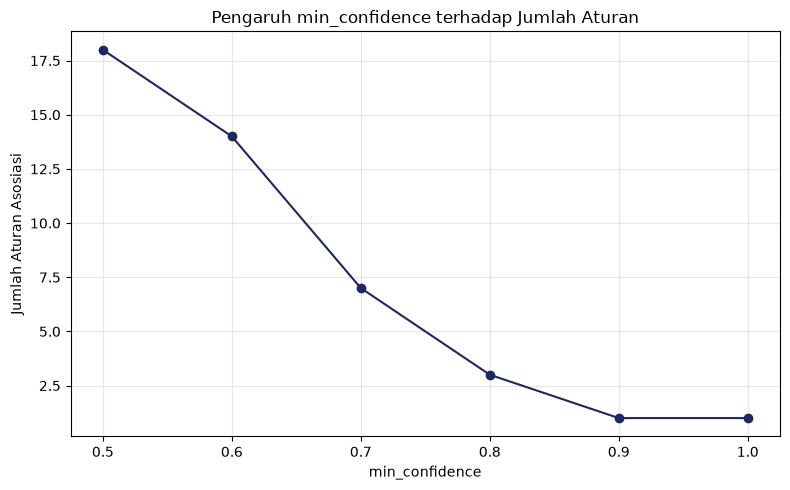

In [6]:
sweep_conf = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
jumlah_rules = []

for c in sweep_conf:
    r = association_rules(
        freq_apriori_015,
        metric='confidence',
        min_threshold=c
    )

    jumlah_rules.append(len(r))
    print(f'min_confidence={c:.1f}: {len(r):2d} aturan')

plt.figure(figsize=(8, 5))
plt.plot(
    sweep_conf,
    jumlah_rules,
    marker='o',
    color='#1E2761'
)

plt.xlabel('min_confidence')
plt.ylabel('Jumlah Aturan Asosiasi')
plt.title('Pengaruh min_confidence terhadap Jumlah Aturan')
plt.xticks(sweep_conf)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Analisis grafik:**

Berdasarkan hasil pengujian, jumlah aturan asosiasi menurun seiring dengan meningkatnya nilai `min_confidence`. Pada ambang 0.5 terdapat 18 aturan, kemudian berkurang menjadi 14 aturan pada 0.6, 7 aturan pada 0.7, 3 aturan pada 0.8, dan masing-masing 1 aturan pada 0.9 serta 1.0.

Penurunan tersebut menunjukkan bahwa semakin tinggi nilai minimum confidence, semakin ketat persyaratan suatu aturan untuk dipertahankan. Hanya aturan dengan nilai confidence yang memenuhi ambang batas yang akan ditampilkan.

### 4. Diskusi trade-off

Berdasarkan hasil eksperimen, penggunaan `min_confidence` yang rendah menghasilkan lebih banyak aturan asosiasi. Pada nilai 0.5 ditemukan 18 aturan, sehingga lebih banyak pola hubungan antaritem yang dapat diamati. Namun, aturan dengan confidence yang lebih rendah berisiko kurang kuat untuk dijadikan dasar rekomendasi bisnis.

Sebaliknya, penggunaan `min_confidence` yang tinggi menghasilkan lebih sedikit aturan. Pada nilai 0.7 hanya tersisa 7 aturan, sedangkan pada nilai 0.9 dan 1.0 masing-masing hanya ditemukan 1 aturan. Aturan yang lolos memiliki tingkat confidence lebih tinggi, tetapi terlalu tingginya ambang batas dapat menghilangkan pola lain yang sebenarnya masih relevan.

Dengan demikian, pemilihan nilai `min_confidence` perlu disesuaikan dengan tujuan analisis. Ambang batas rendah dapat digunakan untuk mengeksplorasi lebih banyak pola, sedangkan ambang batas tinggi digunakan ketika analisis lebih mengutamakan aturan dengan confidence yang kuat. Pada dataset ini, nilai 0.5 memberikan lebih banyak aturan untuk dieksplorasi, sementara nilai 0.7 menyaring aturan menjadi lebih terbatas.